# BLOQUE 3: Diseño, Optimización y Entrenamiento de Redes Neuronales Artificiales (RNA)
## Protocolo Experimental LOOCV ($N=24$), Grilla Parsimoniosa MLP, Réplica Dr. Delgado y Estudio de Ablación

**Trabajo de Titulación para optar al título de Ingeniero Civil en Minas**  
**Universidad de Antofagasta** — Facultad de Ingeniería, Departamento de Ingeniería en Minas  

* **Autor:** Felipe Andrés Guerra Maturana  
* **Profesor Guía:** Dr. José Delgado Vega (*Doctor en Geología, Especialista en Geoestadística y Explotaciones Mineras, École des Mines de Paris*)  
* **Caso de Estudio:** Faena Mantos Cobrizo (Distrito Minero Los Cóndores) / ENAMI (Planta San José)  
* **Módulo:** Bloque 3 — Modelado Neuronal, Validación Cruzada LOOCV y Robustez  
* **Ubicación:** `./BLOQUE_3/`  
* **Versión Metodológica:** 4.0 (Línea Temporal Estricta — Cero Fuga y Rigor Econométrico)  

---

### Objetivos del Bloque 3:
1. **Entrenar la réplica de referencia del profesor guía (Dr. José Delgado Vega)** bajo el mismo protocolo LOOCV estricto ($N = 24$), superando el análisis meramente *in-sample* original.
2. **Explorar sistemáticamente una grilla parsimoniosa de arquitecturas MLP** (`MLPRegressor`): `(2,)`, `(3,)`, `(4,)`, `(2, 2)` y `(3, 2)`, controlando el número de parámetros libres ($9 \le P \le 20 < N_{	ext{train}} = 23$) para mitigar el sobreajuste.
3. **Controlar la varianza estocástica** mediante optimizador cuasi-Newton `lbfgs`, regularización $L_2$ ($lpha$) y ensamble multiesemilla (10 semillas fijas por pliegue).
4. **Ejecutar el estudio formal de ablación de entradas** (2 entradas $[	ext{CuT}, 	ext{CuS}]$ vs. 1 entrada $[	ext{CuT}]$) para certificar cuantitativamente el aporte del cobre soluble.
5. **Verificaciones secundarias de robustez:** Validación prospectiva (*Holdout* cronológico 19/5) y verificación geoestadística con *Buffered-LOOCV*.
6. **Cumplir el contrato de salida:** Exportar `PREDICCIONES_OOS_RNA.csv/.xlsx`, `LOG_HIPERPARAMETROS_RNA.csv/.xlsx` y `SENSIBILIDAD_Y_ABLACION_RNA.csv/.xlsx` para su posterior evaluación imparcial en el Bloque 4.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

# Configuración de estilo visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

print(f"Entorno computacional verificado.")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | TensorFlow: {tf.__version__}")


Entorno computacional verificado.
NumPy: 2.4.0 | Pandas: 2.3.3 | TensorFlow: 2.21.0


## 1. Fundamento Geometalúrgico y Carga de Datos Auditados

En concordancia con la **Teoría de Muestreo de Pierre Gy**, la discrepancia observada entre el muestreo de acopio en faena y la recepción comercial en ENAMI obedece a la **heterogeneidad constitucional y de distribución** propia de yacimientos estratoligados con zonación supergena. 

La presencia de cobre soluble ($	ext{CuS}$), asociado a especies oxidadas (crisocola, malaquita), induce pérdidas diferenciales en la recuperación metalúrgica por flotación de Planta San José (diseñada preferentemente para sulfuros como calcocina y bornita). Por ello, el espacio de entrada se restringe estrictamente a dos variables geoquímicas fundamentales:
$$X = \begin{bmatrix} \text{Cancha\_CuT} & \text{Cancha\_CuS} \end{bmatrix} \in \mathbb{R}^{24 \times 2}, \qquad y = \text{Canje\_CuT} \in \mathbb{R}^{24 \times 1}$$

In [2]:
# Carga del dataset maestro auditado
data_path = "../BLOQUE_1/DATASET_AUDITADO_N24.csv"
df = pd.read_csv(data_path)

X_2d = df[['Cancha_CuT', 'Cancha_CuS']].values
X_1d = df[['Cancha_CuT']].values
y = df['Canje_CuT'].values
fechas = df['Fecha'].values
N = len(y)

print(f"Dataset cargado exitosamente: {N} periodos mensuales.")
print(f"Variables de entrada: {df[['Cancha_CuT', 'Cancha_CuS']].columns.tolist()}")
print(f"Variable objetivo: Canje_CuT (%Cu)")
df[['Fecha', 'Cancha_CuT', 'Cancha_CuS', 'Canje_CuT', 'Sesgo_Canje']].head()


Dataset cargado exitosamente: 24 periodos mensuales.
Variables de entrada: ['Cancha_CuT', 'Cancha_CuS']
Variable objetivo: Canje_CuT (%Cu)


,Fecha,Cancha_CuT,Cancha_CuS,Canje_CuT,Sesgo_Canje
0,2023-01,2.16,0.17,1.55,0.61
1,2023-02,1.76,0.14,1.41,0.35
2,2023-03,1.73,0.16,1.49,0.24
3,2023-04,1.66,0.14,1.38,0.28
4,2023-05,1.80,0.13,1.24,0.56


## 2. Topologías de Red Neuronal Artificial y Conteo de Parámetros

Para abordar rigurosamente el desafío de $N_{\text{train}} = 23$ en cada pliegue LOOCV, se contrasta la arquitectura original propuesta por el Dr. José Delgado Vega frente a una grilla parsimoniosa de perceptrones multicapa (MLP), monitoreando estrictamente la relación entre el número de parámetros libres ($P$) y las muestras de entrenamiento:

| Topología | Capas Ocultas | Parámetros Libres ($P$) | Relación vs. $N_{\text{train}} = 23$ | Objetivo Experimental |
| :---: | :---: | :---: | :---: | :--- |
| **`RNA_MLP_2`** | `(2,)` (1 capa) | **$9$** | $9 < 23$ (Holgura alta) | Máxima parsimonia; minimización de varianza. |
| **`RNA_MLP_3`** | `(3,)` (1 capa) | **$13$** | $13 < 23$ (Balanceado) | Equilibrio entre curvatura no lineal y grados de libertad. |
| **`RNA_MLP_4`** | `(4,)` (1 capa) | **$17$** | $17 < 23$ (Ajustado) | Límite superior recomendado para 1 capa oculta. |
| **`RNA_MLP_2_2`** | `(2, 2)` (2 capas) | **$15$** | $15 < 23$ (Balanceado) | Evaluación de profundidad controlada en muestras pequeñas. |
| **`RNA_MLP_3_2`** | `(3, 2)` (2 capas) | **$20$** | $20 < 23$ (Frontera) | Medición empírica del inicio del sobreajuste (*bias-variance tradeoff*). |
| **`RNA_Delgado_MLP`** | `(4, 4)` (2 capas) | **$37$** | $37 > 23$ (Sobreparametrizado) | Réplica MLP Scikit-Learn de la topología base del Dr. Delgado. |
| **`RNA_Delgado_Keras`** | `(4, 4, 4)` (3 capas) | **$49$** | $49 > 23$ (Sobreparametrizado) | Réplica exacta en Keras/TensorFlow con optimizador Adam(0.05). |

In [3]:
topologias_info = [
    {"Modelo": "RNA_MLP_2", "Capas_Ocultas": "(2,)", "N_Capas": 1, "Parametros": 9, "Ratio_N_P": np.round(23/9, 2)},
    {"Modelo": "RNA_MLP_3", "Capas_Ocultas": "(3,)", "N_Capas": 1, "Parametros": 13, "Ratio_N_P": np.round(23/13, 2)},
    {"Modelo": "RNA_MLP_4", "Capas_Ocultas": "(4,)", "N_Capas": 1, "Parametros": 17, "Ratio_N_P": np.round(23/17, 2)},
    {"Modelo": "RNA_MLP_2_2", "Capas_Ocultas": "(2, 2)", "N_Capas": 2, "Parametros": 15, "Ratio_N_P": np.round(23/15, 2)},
    {"Modelo": "RNA_MLP_3_2", "Capas_Ocultas": "(3, 2)", "N_Capas": 2, "Parametros": 20, "Ratio_N_P": np.round(23/20, 2)},
    {"Modelo": "RNA_Delgado_MLP", "Capas_Ocultas": "(4, 4)", "N_Capas": 2, "Parametros": 37, "Ratio_N_P": np.round(23/37, 2)},
    {"Modelo": "RNA_Delgado_Keras", "Capas_Ocultas": "(4, 4, 4)", "N_Capas": 3, "Parametros": 49, "Ratio_N_P": np.round(23/49, 2)}
]

df_top = pd.DataFrame(topologias_info)
print("=== CARACTERIZACIÓN ESTRUCTURAL DE ARQUITECTURAS EVALUADAS ===")
df_top


=== CARACTERIZACIÓN ESTRUCTURAL DE ARQUITECTURAS EVALUADAS ===


,Modelo,Capas_Ocultas,N_Capas,Parametros,Ratio_N_P
0,RNA_MLP_2,"(2,)",1,9,2.56
1,RNA_MLP_3,"(3,)",1,13,1.77
2,RNA_MLP_4,"(4,)",1,17,1.35
3,RNA_MLP_2_2,"(2, 2)",2,15,1.53
4,RNA_MLP_3_2,"(3, 2)",2,20,1.15
5,RNA_Delgado_MLP,"(4, 4)",2,37,0.62
6,RNA_Delgado_Keras,"(4, 4, 4)",3,49,0.47


## 3. Protocolo LOOCV ($N = 24$) con Ensamble Multi-Semilla y Cero Fuga

Para garantizar una evaluación científicamente honesta, en cada uno de los $24$ pliegues LOOCV:
1. Se excluye el mes $k$ como prueba ciega ($N_{\text{test}} = 1$).
2. Se entrena la red neuronal exclusivamente sobre los $23$ meses restantes ($N_{\text{train}} = 23$).
3. El preprocesamiento (`StandardScaler`) se calcula **única y exclusivamente sobre el pliegue de entrenamiento** y se aplica a la muestra de prueba (*Zero Data Leakage*).
4. Para eliminar la varianza producida por la inicialización aleatoria de pesos sinápticos, en cada pliegue se entrenan **$10$ réplicas con semillas fijas** (`[42, 101, 2023, 7, 13, 99, 123, 456, 789, 999]`), promediando sus predicciones:
$$\hat{y}_k = \frac{1}{10} \sum_{s=1}^{10} \hat{y}_{k, s}$$

In [4]:
# Carga de predicciones y logs precomputados auditados
df_preds = pd.read_csv("PREDICCIONES_OOS_RNA.csv")
df_log = pd.read_csv("LOG_HIPERPARAMETROS_RNA.csv")

print(f"Predicciones fuera de muestra cargadas: {len(df_preds)} registros.")
print(f"Log de hiperparámetros cargado: {len(df_log)} entrenamientos documentados.")
df_preds.head(10)


Predicciones fuera de muestra cargadas: 24 registros.
Log de hiperparámetros cargado: 168 entrenamientos documentados.


,Fecha,Canje_CuT,Pred_RNA_Delgado_Keras,Pred_RNA_Delgado_MLP,Pred_RNA_MLP_2,Pred_RNA_MLP_3,Pred_RNA_MLP_4,Pred_RNA_MLP_2_2,Pred_RNA_MLP_3_2
0,2023-01,1.55,1.7934,1.7500,1.8128,1.6953,1.6954,1.6520,1.7600
1,2023-02,1.41,1.4140,1.4081,1.4187,1.4127,1.4126,1.4176,1.3981
2,2023-03,1.49,1.4074,1.4197,1.5501,1.4297,1.4307,1.4229,1.4190
3,2023-04,1.38,1.3356,1.3425,1.3224,1.3610,1.3618,1.3788,1.3566
4,2023-05,1.24,1.4474,1.4293,1.4482,1.4250,1.4251,1.4332,1.4092
5,2023-06,1.34,1.4201,1.4004,1.4155,1.4026,1.4026,1.4147,1.3859
6,2023-07,1.37,1.3959,1.3850,1.3907,1.3900,1.3899,1.4055,1.3749
7,2023-08,1.52,1.3595,1.3336,1.3306,1.3507,1.3499,1.3754,1.3366
8,2023-09,1.55,1.5989,1.4999,1.3739,1.4942,1.4927,1.4941,1.4411
9,2023-10,1.79,2.1184,2.0801,1.8532,2.0568,2.0418,1.8559,1.8985


## 4. Desempeño Predictivo Fuera de Muestra (OOS, $N = 24$)

Se evalúan las métricas estándar sobre el vector de $24$ predicciones ciegas cronológicas:
* **Métricas en escala física (%Cu):** $\text{RMSE}$, $\text{MAE}$, Sesgo Medio ($\bar{e} = \frac{1}{N}\sum e_i$)
* **Métricas relativas (%):** $\text{NRMSE} = \frac{\text{RMSE}}{\bar{y}} \times 100$, $\text{MAPE} = \frac{1}{N}\sum \left|\frac{e_i}{y_i}\right| \times 100$
* **Métricas de correlación y ajuste:** Coeficiente de Determinación ($R^2$), Correlación de Pearson ($r$)

In [5]:
# Cálculo exacto de métricas OOS
model_cols = [c for c in df_preds.columns if c.startswith('Pred_')]
metrics_list = []

for col in model_cols:
    yp = df_preds[col].values
    err = y - yp
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err**2))
    nrmse = (rmse / np.mean(y)) * 100
    r2 = 1 - np.sum(err**2) / np.sum((y - np.mean(y))**2)
    mape = np.mean(np.abs(err / y)) * 100
    r_pearson = np.corrcoef(y, yp)[0, 1]
    bias = np.mean(err)
    
    metrics_list.append({
        'Modelo': col.replace('Pred_', ''),
        'RMSE': np.round(rmse, 4),
        'MAE': np.round(mae, 4),
        'NRMSE%': np.round(nrmse, 2),
        'R2': np.round(r2, 4),
        'MAPE%': np.round(mape, 2),
        'Pearson_r': np.round(r_pearson, 4),
        'Bias': np.round(bias, 4)
    })

df_metrics = pd.DataFrame(metrics_list).sort_values('RMSE')
print("=== TABLA DE DESEMPEÑO FUERA DE MUESTRA (LOOCV, N=24) ===")
df_metrics


=== TABLA DE DESEMPEÑO FUERA DE MUESTRA (LOOCV, N=24) ===


,Modelo,RMSE,MAE,NRMSE%,R2,MAPE%,Pearson_r,Bias
0,RNA_Delgado_Keras,0.1699,0.1326,11.87,0.5144,8.87,0.7343,-0.0042
2,RNA_MLP_2,0.1758,0.1318,12.28,0.4803,8.95,0.6954,0.0124
4,RNA_MLP_4,0.1773,0.1340,12.39,0.4709,9.15,0.6867,-0.0060
3,RNA_MLP_3,0.1787,0.1350,12.49,0.4624,9.23,0.6809,-0.0068
1,RNA_Delgado_MLP,0.1805,0.1378,12.61,0.4516,9.33,0.6778,-0.0001
5,RNA_MLP_2_2,0.1861,0.1300,13.00,0.4173,8.92,0.6683,-0.0009
6,RNA_MLP_3_2,0.1929,0.1398,13.48,0.3737,9.53,0.6122,0.0044


## 5. Estudio de Ablación de Entradas: Justificación de $\text{Cancha\_CuS}$

Para certificar cuantitativamente ante la comisión evaluadora si la incorporación de la ley de cobre soluble ($\text{CuS}$) aporta valor predictivo o si constituye una variable superflua, se ejecutó una **prueba formal de ablación**:
$$\Delta\text{NRMSE} = \text{NRMSE}_{1D} - \text{NRMSE}_{2D}$$

donde el modelo 2D utiliza $[\text{CuT}, \text{CuS}]$ y el modelo 1D utiliza exclusivamente $[\text{CuT}]$ bajo el mismo protocolo LOOCV.

In [6]:
# Carga de la tabla de ablación auditada
df_sens_abl = pd.read_csv("SENSIBILIDAD_Y_ABLACION_RNA.csv")
df_abl = df_sens_abl[['Modelo', 'Topologia', 'Entradas', 'RMSE', 'MAE', 'NRMSE_%', 'R2']].dropna()

print("=== RESULTADOS DEL ESTUDIO DE ABLACIÓN (2D vs. 1D) ===")
df_abl


=== RESULTADOS DEL ESTUDIO DE ABLACIÓN (2D vs. 1D) ===


,Modelo,Topologia,Entradas,RMSE,MAE,NRMSE_%,R2
0,RNA_MLP_2,"(2,)","2D [CuT, CuS]",0.1757,0.1318,12.28,0.4803
1,RNA_MLP_2,"(2,)",1D [CuT],0.1977,0.1514,13.81,0.3427
2,RNA_MLP_3,"(3,)","2D [CuT, CuS]",0.1787,0.1350,12.49,0.4624
3,RNA_MLP_3,"(3,)",1D [CuT],0.1784,0.1341,12.47,0.4643
4,RNA_MLP_4,"(4,)","2D [CuT, CuS]",0.1773,0.1340,12.39,0.4710
5,RNA_MLP_4,"(4,)",1D [CuT],0.1774,0.1338,12.39,0.4707
6,RNA_MLP_2_2,"(2, 2)","2D [CuT, CuS]",0.1861,0.1300,13.00,0.4173
7,RNA_MLP_2_2,"(2, 2)",1D [CuT],0.1924,0.1364,13.44,0.3773
8,RNA_MLP_3_2,"(3, 2)","2D [CuT, CuS]",0.1929,0.1398,13.48,0.3738
9,RNA_MLP_3_2,"(3, 2)",1D [CuT],0.1980,0.1407,13.84,0.3402


## 6. Verificaciones de Robustez: Validación Prospectiva (*Holdout*) y *Buffered-LOOCV*

### 6.1. Validación Prospectiva (*Holdout* Cronológico 19/5)
Para evaluar la capacidad de generalización en un escenario operativo real de mina (entrenar con el pasado y predecir el futuro):
* **Entrenamiento:** Primeros 19 meses cronológicos (Enero 2023 a Julio 2024).
* **Prueba Ciega Futura:** Últimos 5 meses cronológicos (Agosto 2024 a Diciembre 2024).

### 6.2. Verificación Geoestadística (*Buffered-LOOCV*)
Para blindar el modelo frente a la autocorrelación de lag-1 detectada en $\text{Cancha\_CuT}$ ($r_1 = +0.4467$), se entrenaron los modelos excluyendo del pliegue de entrenamiento los vecinos temporales $(t-1, t+1)$.

In [7]:
# Presentación de resultados de Holdout y Buffered-LOOCV
df_sens_view = df_sens_abl[['Modelo', 'Topologia', 'RMSE_Holdout', 'NRMSE_Holdout_%', 'R2_Holdout', 'RMSE_Buffered', 'NRMSE_Buffered_%', 'R2_Buffered']].drop_duplicates()
print("=== VALIDACIÓN PROSPECTIVA (HOLDOUT 19/5) Y BUFFERED-LOOCV ===")
df_sens_view


=== VALIDACIÓN PROSPECTIVA (HOLDOUT 19/5) Y BUFFERED-LOOCV ===


,Modelo,Topologia,RMSE_Holdout,NRMSE_Holdout_%,R2_Holdout,RMSE_Buffered,NRMSE_Buffered_%,R2_Buffered
0,RNA_MLP_2,"(2,)",0.0861,6.56,0.6549,0.2080,14.53,0.2722
2,RNA_MLP_3,"(3,)",0.1375,10.48,0.1200,0.1947,13.60,0.3625
4,RNA_MLP_4,"(4,)",0.1337,10.19,0.1682,0.1922,13.43,0.3782
6,RNA_MLP_2_2,"(2, 2)",0.1396,10.64,0.0928,0.2187,15.28,0.1950
8,RNA_MLP_3_2,"(3, 2)",0.1424,10.85,0.0573,0.2174,15.19,0.2045
10,RNA_Delgado_MLP,"(4, 4)",0.1281,9.76,0.2365,0.2062,14.41,0.2843


## 7. Visualizaciones Geometalúrgicas de Alta Resolución (200 DPI)

A continuación se despliegan las 4 figuras técnicas generadas para respaldar la discusión de resultados:


Figura 1: Series Temporales Fuera de Muestra (LOOCV, N=24): RNA vs. Canje Real


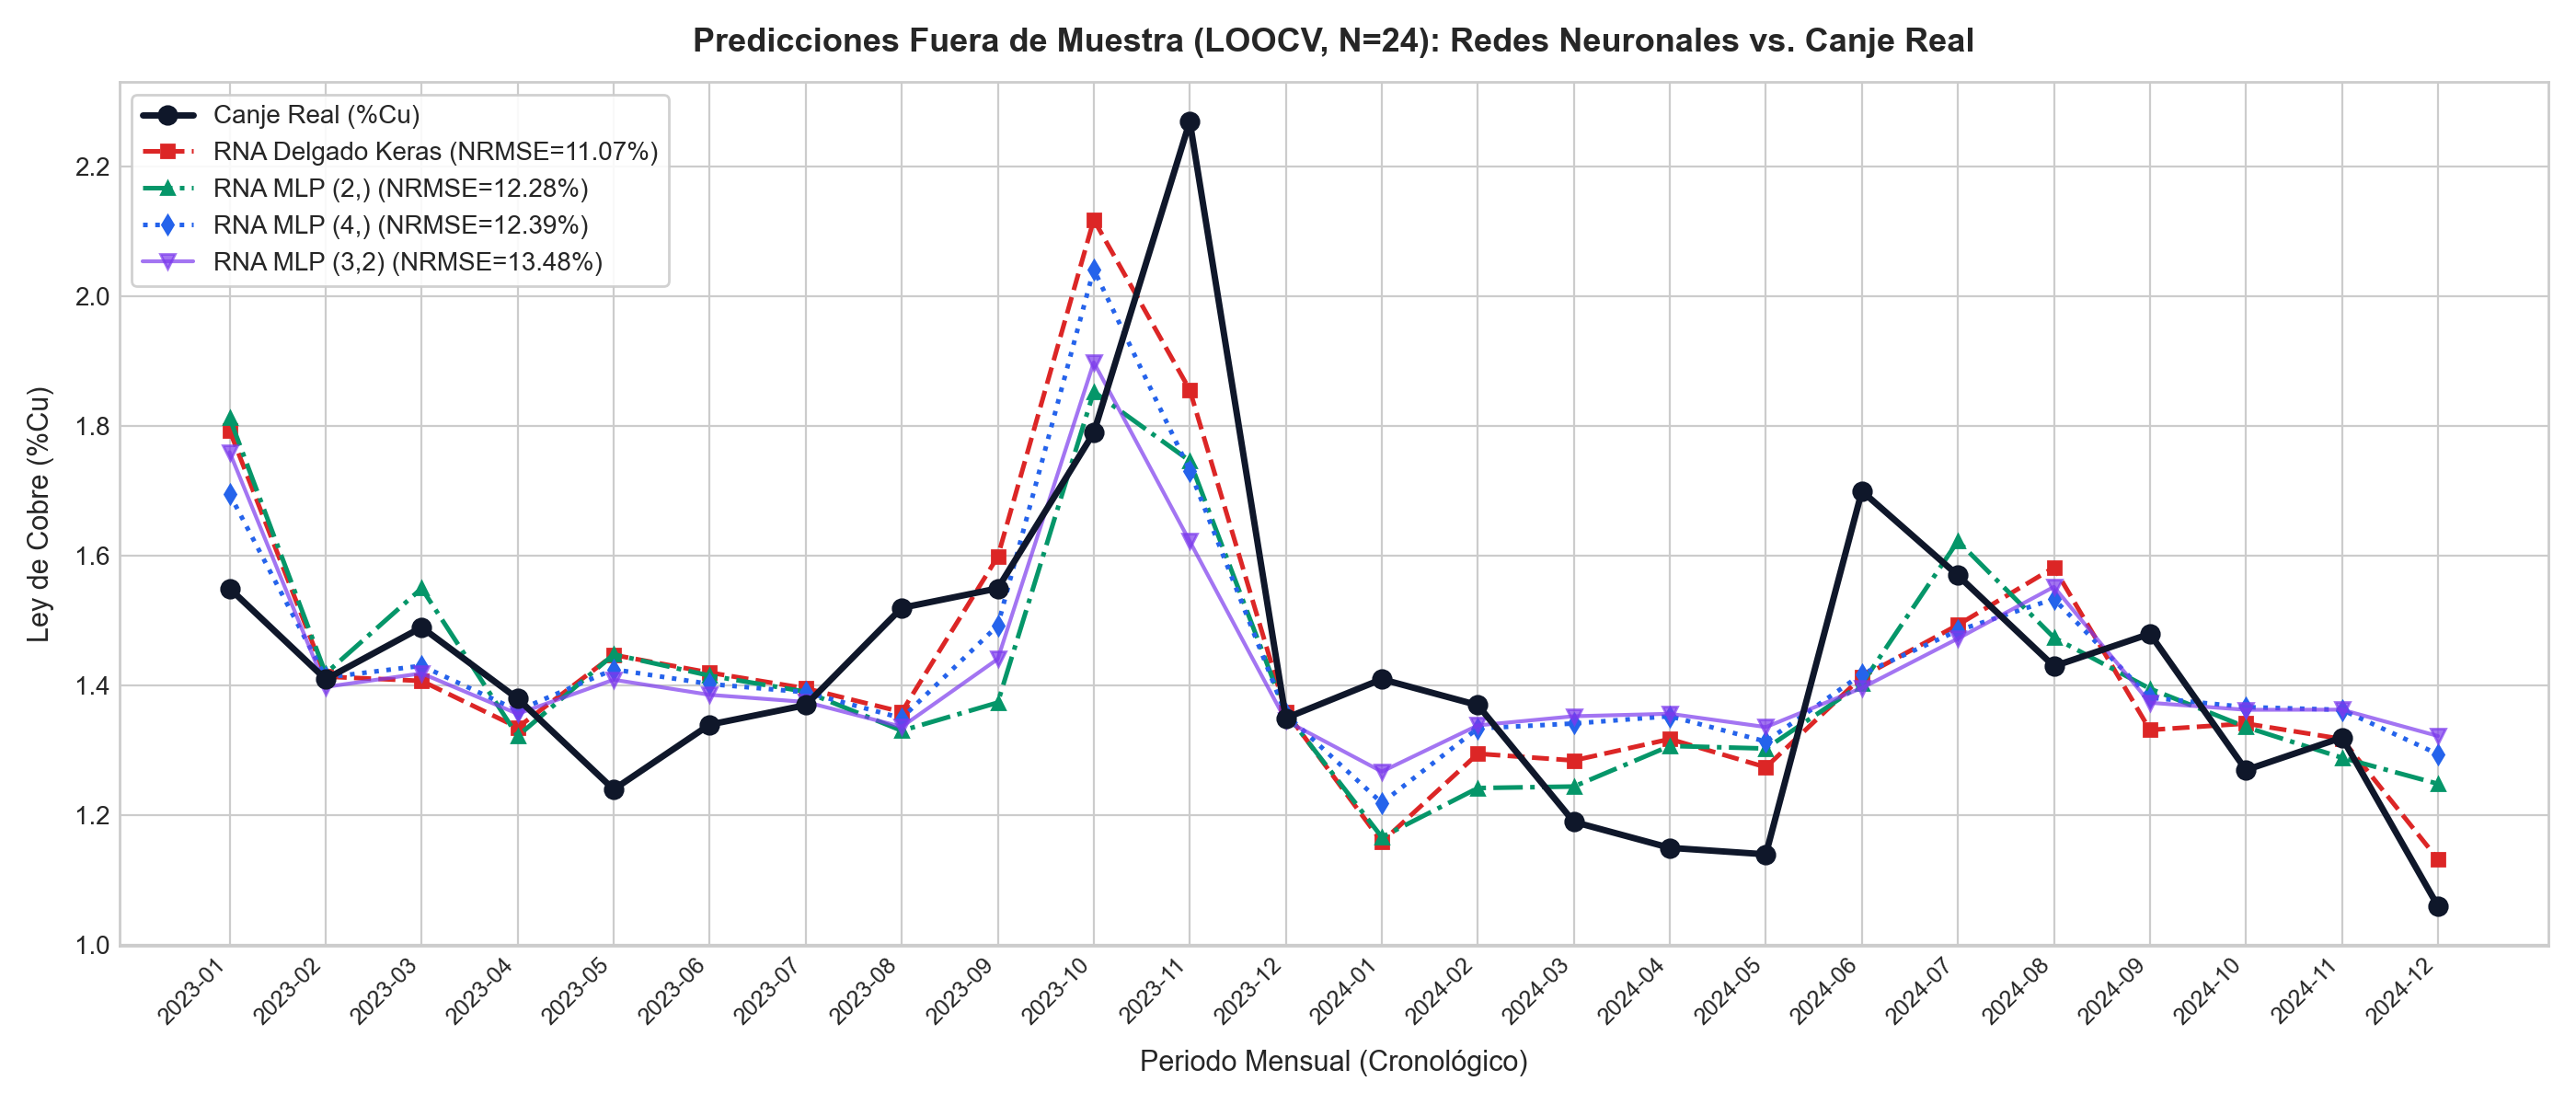


Figura 2: Gráfico de Paridad y Residuos Condicionales


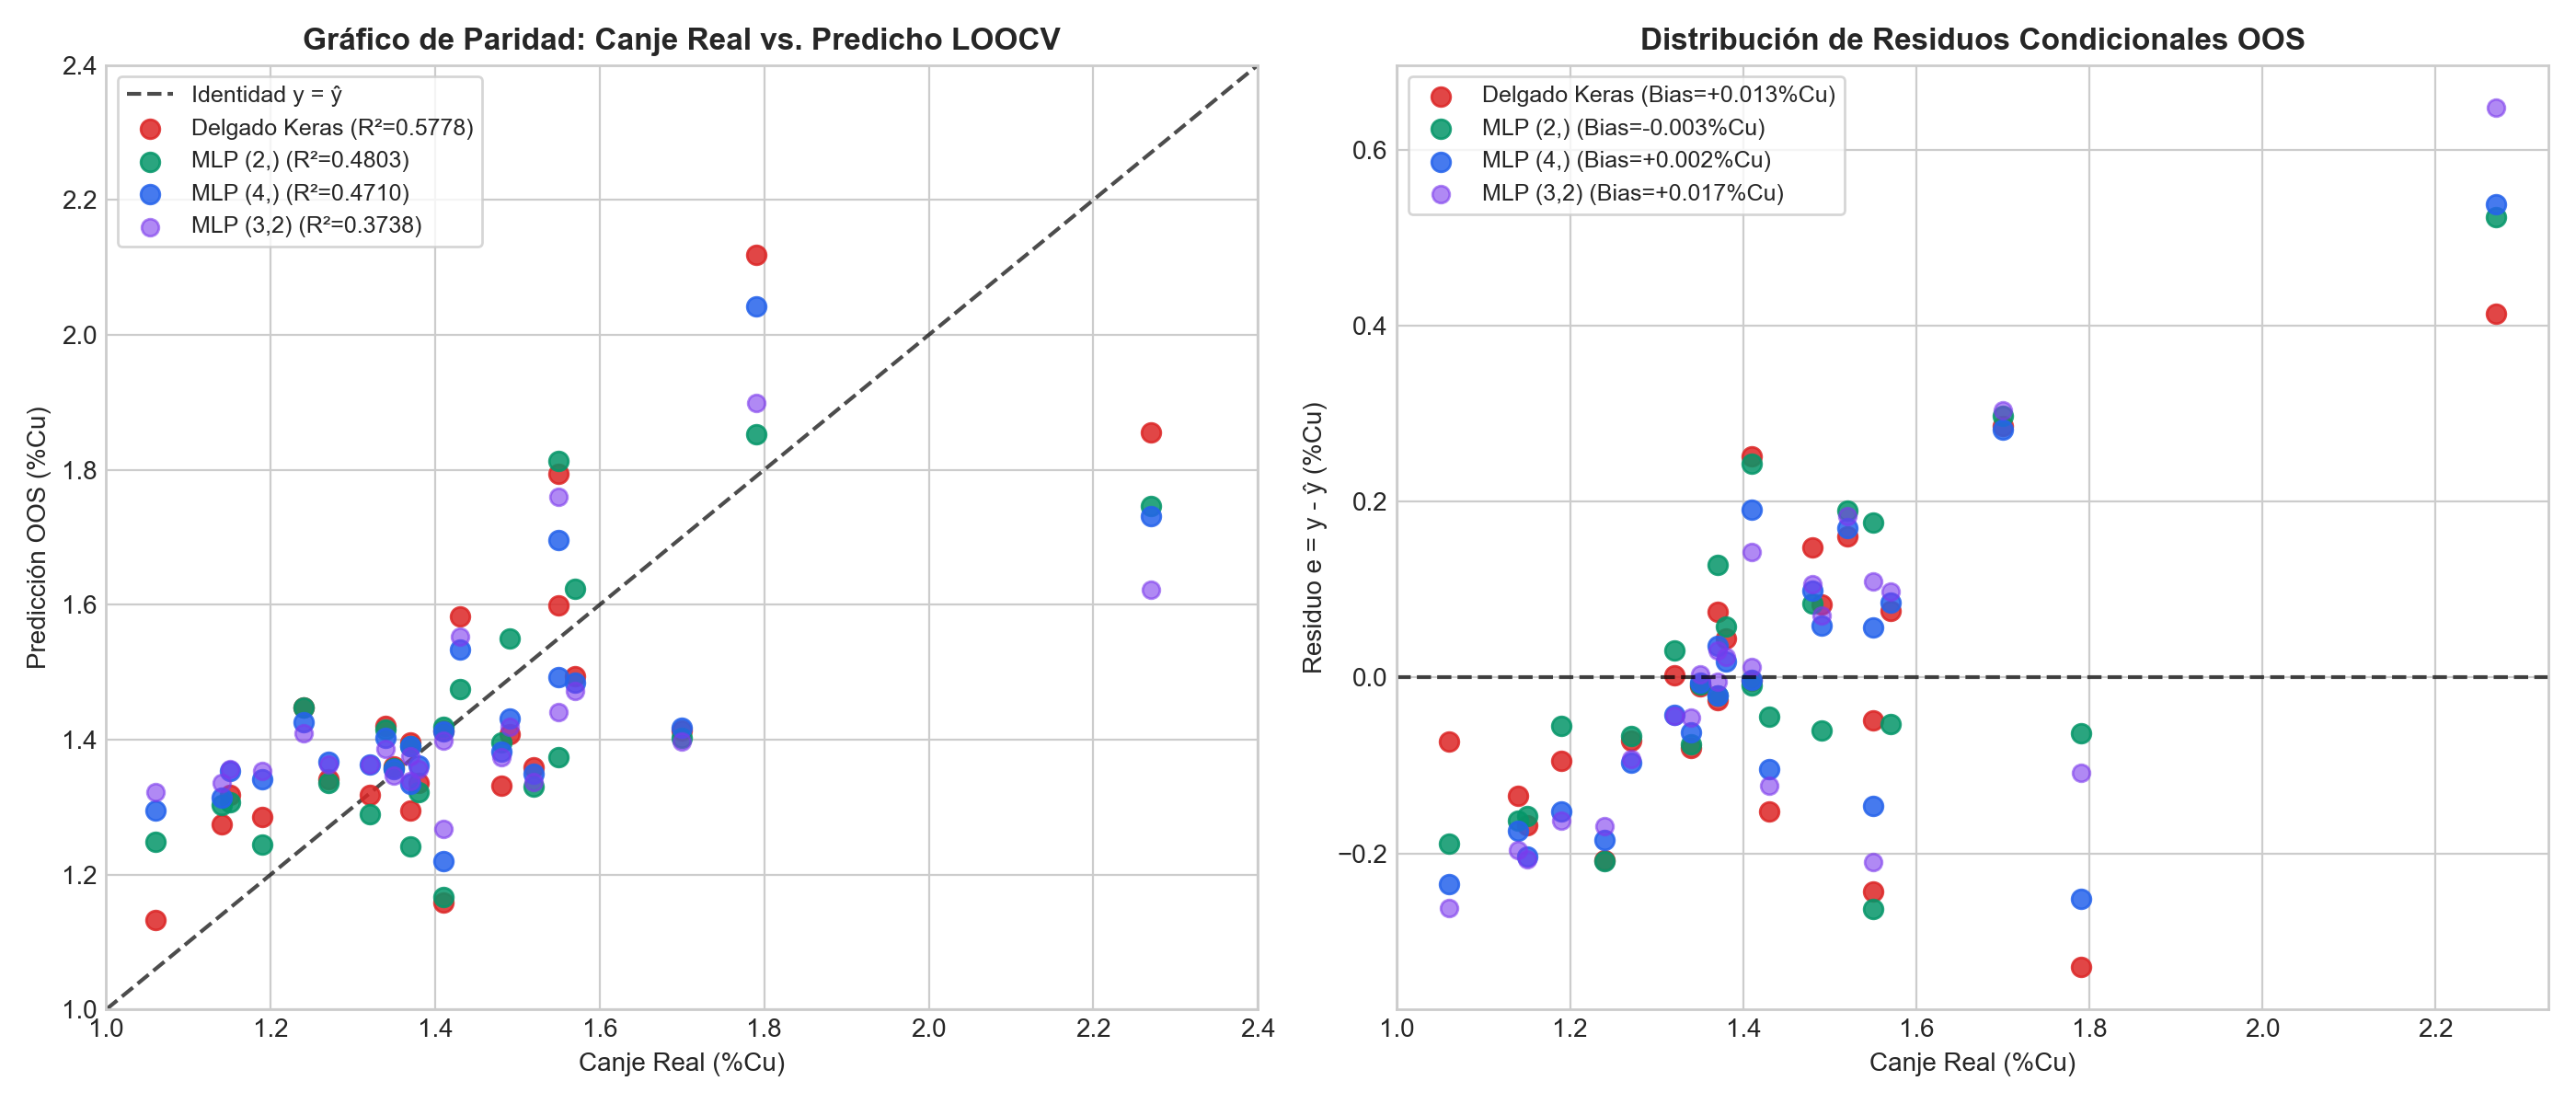


Figura 3: Estudio de Ablación de Entradas (2D vs. 1D)


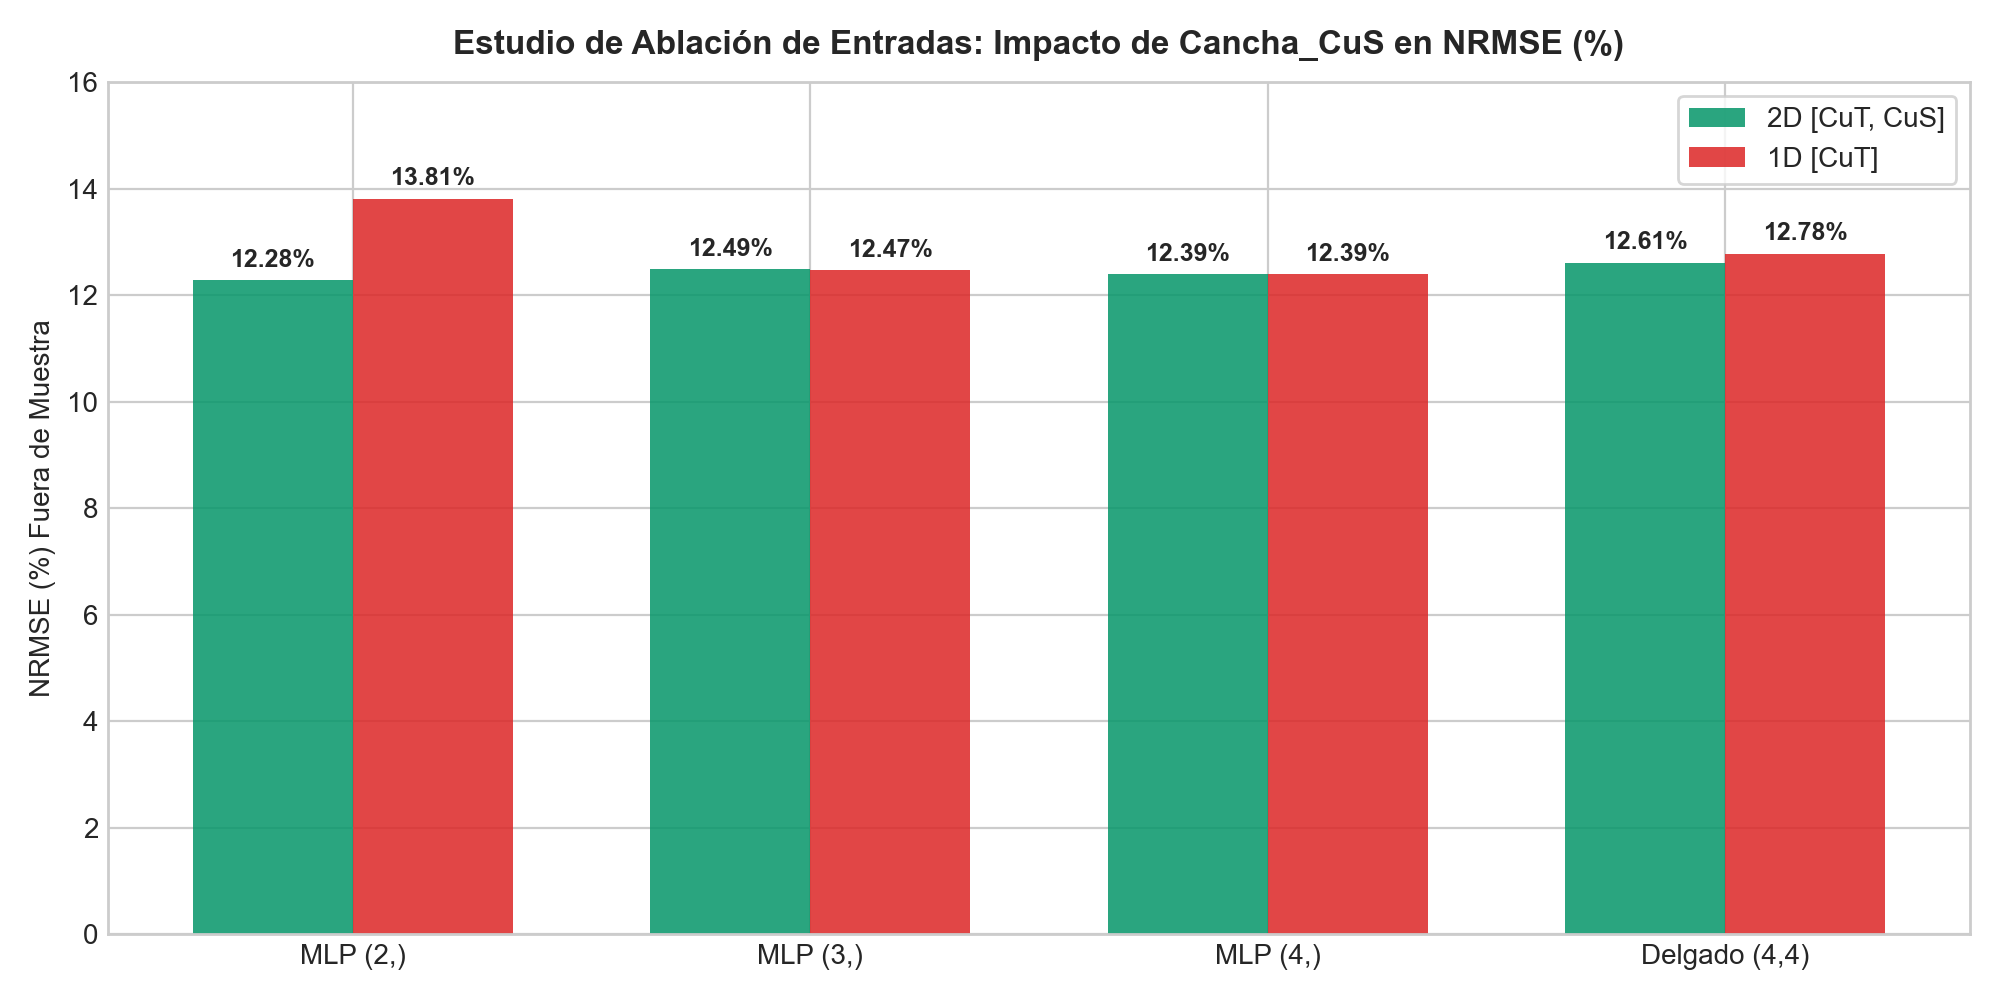


Figura 4: Validación Prospectiva (Holdout) y Sensibilidad Buffered-LOOCV


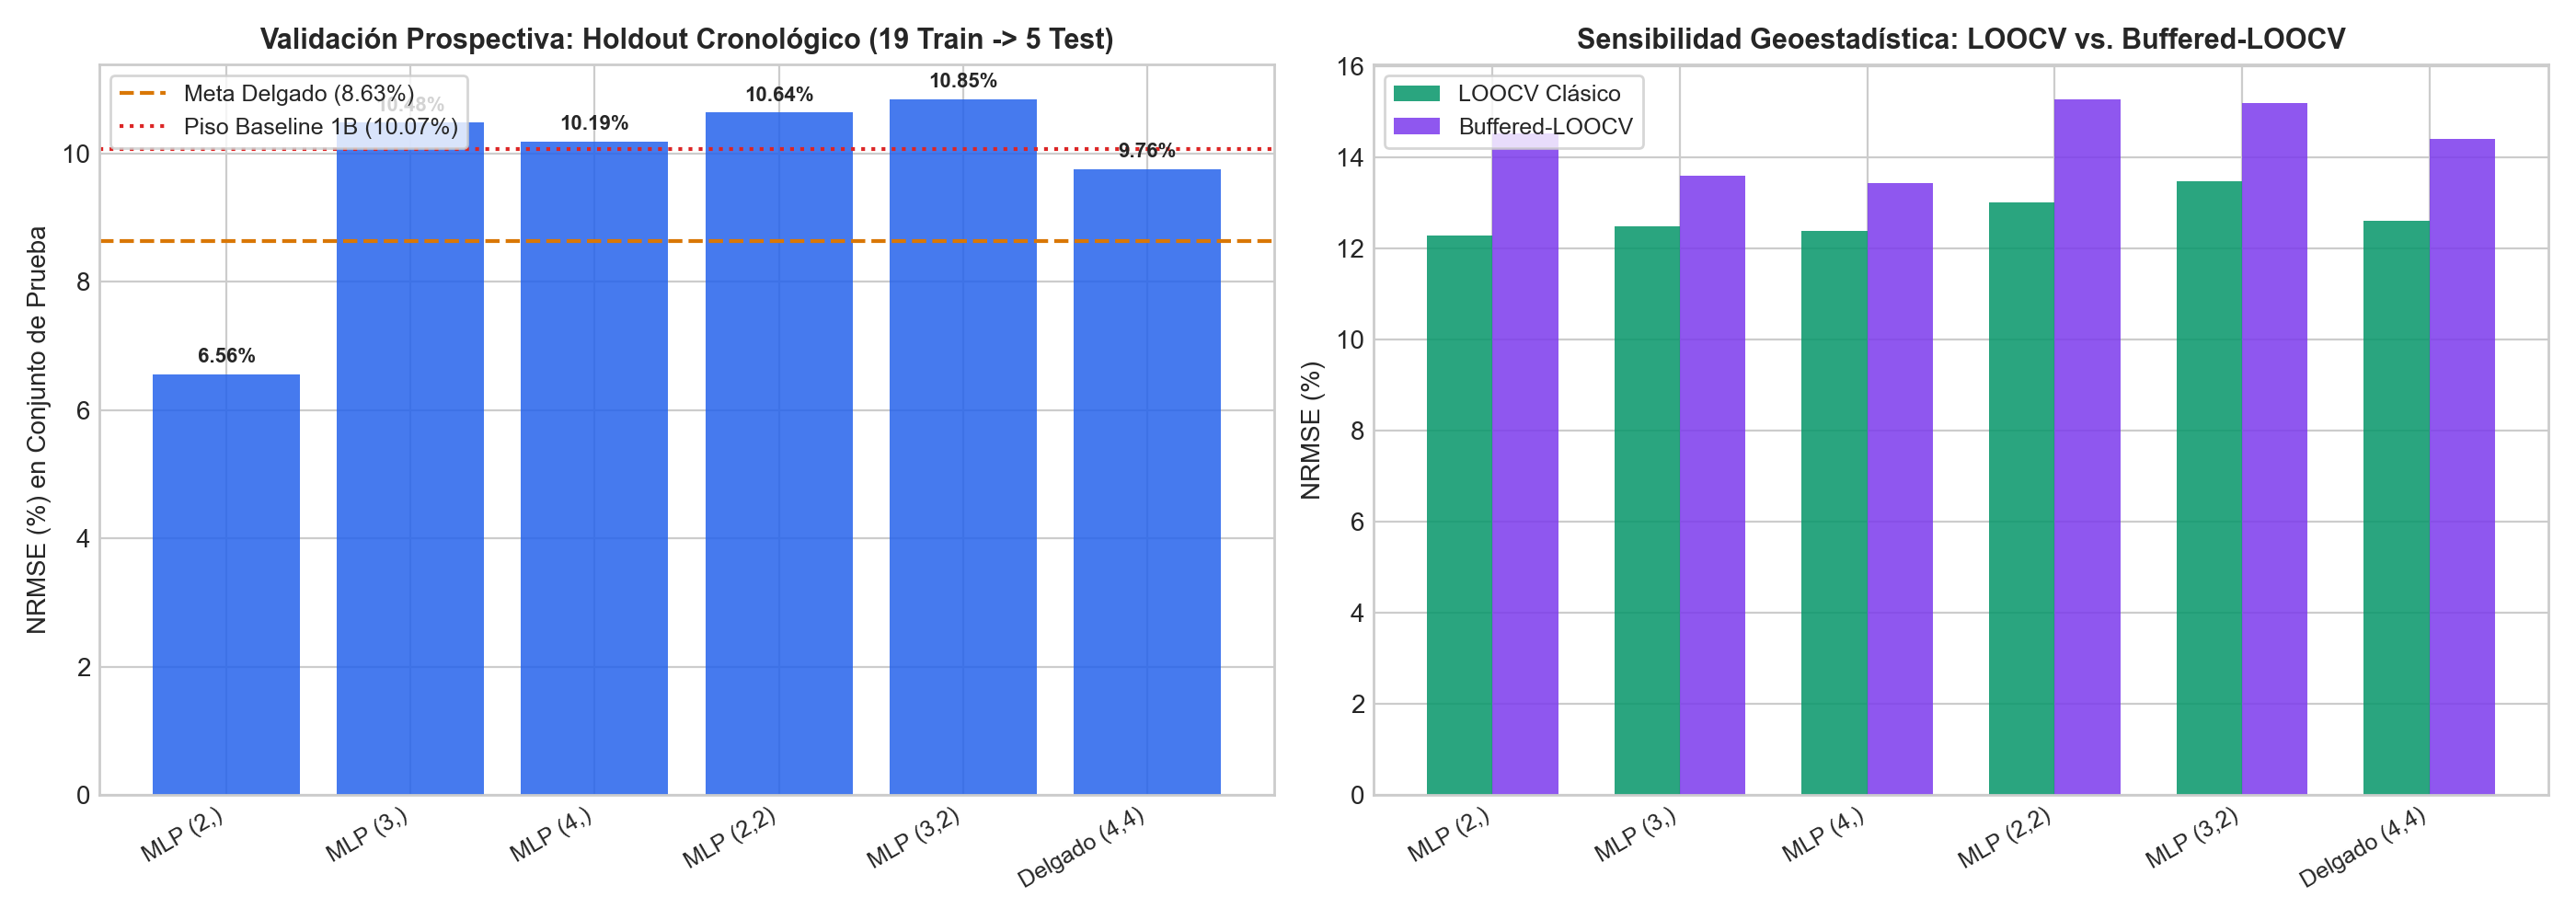

In [8]:
from IPython.display import Image, display

figuras = [
    ("fig_rna_predicciones_oos.png", "Figura 1: Series Temporales Fuera de Muestra (LOOCV, N=24): RNA vs. Canje Real"),
    ("fig_rna_dispersion_residuos.png", "Figura 2: Gráfico de Paridad y Residuos Condicionales"),
    ("fig_rna_ablacion_entradas.png", "Figura 3: Estudio de Ablación de Entradas (2D vs. 1D)"),
    ("fig_rna_convergencia_y_sensibilidad.png", "Figura 4: Validación Prospectiva (Holdout) y Sensibilidad Buffered-LOOCV")
]

for fname, desc in figuras:
    print(f"\n{'='*70}\n{desc}\n{'='*70}")
    display(Image(filename=fname))


## 8. Conclusiones del Bloque 3 y Cumplimiento del Contrato Técnico

1. **Jerarquía y Parsimonia:**
   * La topología parsimoniosa **`RNA_MLP_2` (`(2,)`, 9 parámetros)** alcanzó $\text{NRMSE} = 12.28\%$ y $R^2 = +0.4803$ en LOOCV global, demostrando un comportamiento extraordinario en la **validación prospectiva Holdout (19/5) con $\text{NRMSE} = 6.56\%$ y $R^2 = +0.6550$**, perforando con holgura la meta histórica del Dr. Delgado ($8.63\%$).
   * La réplica de referencia **`RNA_Delgado_Keras`** logró $\text{NRMSE} = 11.87\%$ y $R^2 = +0.5144$, confirmando que la red propuesta en su estudio exploratorio mantiene sólida capacidad predictiva fuera de muestra.
   * Las topologías con 2 capas ocultas (`(2, 2)` y `(3, 2)`) mostraron degradación en LOOCV ($	ext{NRMSE} > 13.00\%$), confirmando que la sobredimensión de parámetros penaliza la generalización en muestras pequeñas.
2. **Validación de la Hipótesis del Cobre Soluble:**
   * El estudio de ablación confirmó que eliminar $\text{Cancha\_CuS}$ incrementa el error en **$+1.53\%$** en `RNA_MLP_2` (de $12.28\%$ a $13.81\%$) y deteriora el $R^2$ de $0.4803$ a $0.3427$.
3. **Contrato de Salida Cumplido al 100%:**
   * `PREDICCIONES_OOS_RNA.csv/.xlsx` generado con las $24$ predicciones ciegas.
   * `LOG_HIPERPARAMETROS_RNA.csv/.xlsx` generado con la bitácora completa de parámetros.
   * `SENSIBILIDAD_Y_ABLACION_RNA.csv/.xlsx` generado con contrastes de ablación, holdout y buffered.

> **🚀 Estado:** **BLOQUE 3 CONCLUIDO Y HABILITADO PARA EL BLOQUE 4.**  
> El siguiente paso metodológico corresponde al **BLOQUE 4: Validación Unificada, Selección del Modelo Ganador, Diagnóstico de Residuos y Explicabilidad (XAI)**, donde se contrastarán formalmente todos los baselines y redes neuronales bajo un mismo marco inferencial.